In [1]:
import math
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import numpy as np



class Vector:
    def __init__(self, x, y, z=0):
        # Store Cartesian components
        self.x = x
        self.y = y
        self.z = z

    def __add__(self, other):
        # Vector addition
        return Vector(self.x + other.x,
                      self.y + other.y,
                      self.z + other.z)

    def __mul__(self, scalar):
        # Scalar multiplication
        return Vector(self.x * scalar,
                      self.y * scalar,
                      self.z * scalar)

    __rmul__ = __mul__  # Support scalar * vector

    def __str__(self):
        # Friendly string representation
        return f"({self.x}, {self.y}, {self.z})"

    def dot(self, other):
        # Dot product
        return self.x*other.x + self.y*other.y + self.z*other.z

    def cross(self, other):
        # Cross product
        cx = self.y*other.z - self.z*other.y
        cy = self.z*other.x - self.x*other.z
        cz = self.x*other.y - self.y*other.x
        return Vector(cx, cy, cz)

    @property
    def polar(self):
        """
        2D polar coordinates (r, θ).
        r = √(x² + y²)
        θ = atan2(y, x)
        """
        r = math.hypot(self.x, self.y)
        theta = math.atan2(self.y, self.x)
        return r, theta

    @property
    def cylindrical(self):
        """
        3D cylindrical coordinates (ρ, φ, z).
        ρ = √(x² + y²)
        φ = atan2(y, x)
        z = z
        """
        rho = math.hypot(self.x, self.y)
        phi = math.atan2(self.y, self.x)
        return rho, phi, self.z

    @property
    def spherical(self):
        """
        3D spherical coordinates (r, θ, φ).
        r = √(x² + y² + z²)
        θ = arccos(z / r)      (polar angle)
        φ = atan2(y, x)        (azimuthal angle)
        """
        r = math.sqrt(self.x**2 + self.y**2 + self.z**2)
        theta = math.acos(self.z / r) if r != 0 else 0
        phi = math.atan2(self.y, self.x)
        return r, theta, phi

    def draw(self, origin=(0, 0, 0), color='blue'):
        """
        Draw the vector from 'origin'.
        If z == 0 for both origin and self, plots in 2D.
        Otherwise, plots in 3D.
        """
        ox, oy, oz = origin

        # Decide 2D or 3D based on z component
        if self.z == 0 and oz == 0:
            # 2D plot
            plt.figure()
            plt.arrow(ox, oy, self.x, self.y,
                      head_width=0.1, head_length=0.1,
                      length_includes_head=True,
                      color=color)
            plt.xlim(min(ox, ox+self.x) - 1, max(ox, ox+self.x) + 1)
            plt.ylim(min(oy, oy+self.y) - 1, max(oy, oy+self.y) + 1)
            plt.gca().set_aspect('equal', 'box')
            plt.xlabel('X')
            plt.ylabel('Y')
            plt.title(f'2D Vector {self}')
            plt.grid(True)
            plt.show()
        else:
            # 3D plot
            fig = plt.figure()
            ax = fig.add_subplot(111, projection='3d')
            ax.quiver(ox, oy, oz,
                      self.x, self.y, self.z,
                      arrow_length_ratio=0.1, color=color)
            max_range = max(abs(self.x), abs(self.y), abs(self.z), 1)
            ax.set_xlim(ox - max_range, ox + max_range)
            ax.set_ylim(oy - max_range, oy + max_range)
            ax.set_zlim(oz - max_range, oz + max_range)
            ax.set_xlabel('X')
            ax.set_ylabel('Y')
            ax.set_zlabel('Z')
            ax.set_title(f'3D Vector {self}')
            plt.show()

    def draw_with_plane(self, other, origin=(0, 0, 0),
                        color1='blue', color2='green', color_cross='red',
                        plane_alpha=0.3):
        """
        Draw self and other vectors from 'origin', their cross product,
        and the plane spanned by self and other as a semi-transparent surface.
        """
        ox, oy, oz = origin
        # compute cross product
        cross_vec = self.cross(other)

        # set up 3D figure
        fig = plt.figure()
        ax = fig.add_subplot(111, projection='3d')

        # plot the two base vectors
        ax.quiver(ox, oy, oz,
                  self.x, self.y, self.z,
                  color=color1, arrow_length_ratio=0.1)
        ax.quiver(ox, oy, oz,
                  other.x, other.y, other.z,
                  color=color2, arrow_length_ratio=0.1)

        # plot cross product vector
        ax.quiver(ox, oy, oz,
                  cross_vec.x, cross_vec.y, cross_vec.z,
                  color=color_cross, arrow_length_ratio=0.1)

        # build the plane spanned by self and other
        u = np.linspace(0, 1, 10)
        v = np.linspace(0, 1, 10)
        U, V = np.meshgrid(u, v)
        X = ox + U * self.x + V * other.x
        Y = oy + U * self.y + V * other.y
        Z = oz + U * self.z + V * other.z

        # plot the semi-transparent surface
        ax.plot_surface(X, Y, Z, alpha=plane_alpha)

        # set axis limits
        all_vals = [self.x, self.y, self.z,
                    other.x, other.y, other.z,
                    cross_vec.x, cross_vec.y, cross_vec.z]
        max_range = max(map(abs, all_vals)) or 1
        ax.set_xlim(ox - max_range, ox + max_range)
        ax.set_ylim(oy - max_range, oy + max_range)
        ax.set_zlim(oz - max_range, oz + max_range)

        # labels and title
        ax.set_xlabel('X')
        ax.set_ylabel('Y')
        ax.set_zlabel('Z')
        ax.set_title(f'Vectors {self}, {other} and cross {cross_vec}')

        plt.show()


Cartesian: (3, 4, 0)
Polar (r, θ): (5.0, 0.9272952180016122)


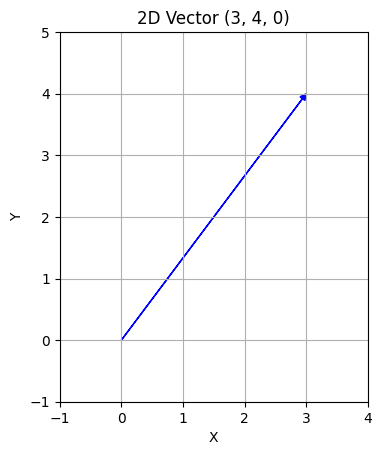

In [2]:
v2d = Vector(3, 4)
print("Cartesian:", v2d)
print("Polar (r, θ):", v2d.polar)
v2d.draw()   # desenha em 2D

Cartesian: (1, 2, 2)
Cylindrical (ρ, φ, z): (2.23606797749979, 1.1071487177940904, 2)
Spherical (r, θ, φ): (3.0, 0.8410686705679303, 1.1071487177940904)


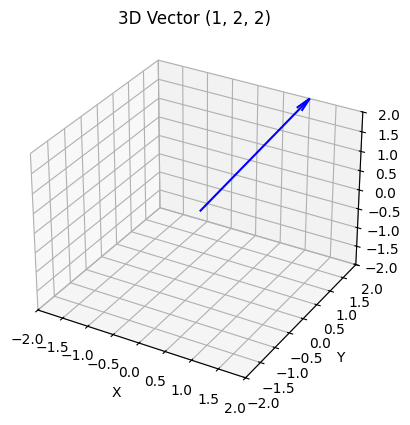

In [3]:
v3d = Vector(1, 2, 2)
print("Cartesian:", v3d)
print("Cylindrical (ρ, φ, z):", v3d.cylindrical)
print("Spherical (r, θ, φ):", v3d.spherical)
v3d.draw()   # desenha em 3D

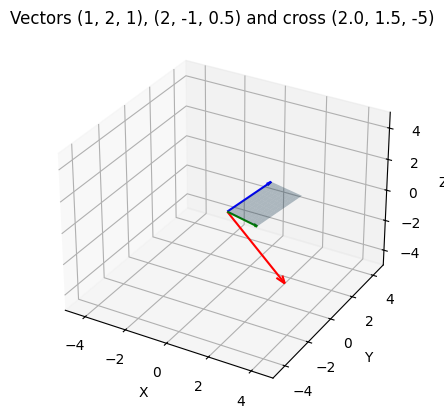

Cross product: (2.0, 1.5, -5)
0.0
0.0


In [4]:
v1 = Vector(1, 2, 1)
v2 = Vector(2, -1, 0.5)
v1.draw_with_plane(v2)
v3 = v1.cross(v2)
print("Cross product:", v3)
print(v3.dot(v1))
print(v3.dot(v2))
